# Extended Data Figure 7

Panels a–j drawn from the source data: per-PSM spectral angles (`Wilhelm_SourceData_ED_Fig7a.parquet`, `Wilhelm_SourceData_ED_Fig7b.parquet`), precision–recall curve points, one row per PSM rank (`Wilhelm_SourceData_ED_Fig7c.parquet`, `..._ED_Fig7d_f.parquet`, `..._ED_Fig7g.parquet`, `..._ED_Fig7h_i.parquet`, `..._ED_Fig7j.parquet`) and n / summary statistics per panel (`Wilhelm_SourceData_ED_Fig7a.csv` ... `Wilhelm_SourceData_ED_Fig7j.csv`).

Data are loaded with `source_data.py` (same folder) from the figshare deposit: set `FIGSHARE_ARTICLE_ID` in the next cell (or the environment variable of the same name), or `SOURCE_DATA_DIR` to a local copy of the files; while the article is private, set `FIGSHARE_TOKEN`. Panels are saved to `regenerated_panels/ED_Fig7/`.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.interpolate import UnivariateSpline

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig7'
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'Prosit-22PTM': '#e1822b', 'MSFragger': 'royalblue', 'AlphaPeptDeep': '#2f7ab9'}
SMOOTH = 0.005  # UnivariateSpline smoothing factor, identical for every curve
LS = {'Non-adjacent': '-', 'Adjacent': '--'}
from matplotlib.lines import Line2D


def two_part_legend(ax, colors, loc='lower left'):
    """Legend: colour = tool / model, line style = site context (true site)."""
    h = [Line2D([], [], color=c, lw=2) for c in colors.values()] + [Line2D([], [], color='k', ls=l) for l in LS.values()]
    ax.legend(h, list(colors) + list(LS), loc=loc, fontsize=8)


def fit_curve(x, y, s=SMOOTH, n=200):
    """Smoothing spline y(x) through the curve points; ties in x collapsed to the last point."""
    d = pd.DataFrame({'x': x, 'y': y}).groupby('x', sort=True)['y'].last()
    if len(d) < 4:
        return d.index.values, d.values
    spline = UnivariateSpline(d.index.values.astype(float), d.values, s=s)
    xs = np.linspace(d.index.min(), d.index.max(), n)
    return xs, np.clip(spline(xs), None, 1.0)  # spline overshoot above precision 1 clipped


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()


readme('ED_Fig7')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 7,a,NaN,Wilhelm_SourceData_ED_Fig7a.parquet; Wilhelm_S...,Spectral angle of PTM-specific ions per PSM (p...,NaN
1,Extended Data Fig. 7,b,NaN,Wilhelm_SourceData_ED_Fig7b.parquet; Wilhelm_S...,Spectral angle of site-specific ions per PSM (...,NaN
2,Extended Data Fig. 7,c,NaN,Wilhelm_SourceData_ED_Fig7c.parquet; Wilhelm_S...,"Precision-recall of phosphosite localisation, ...",NaN
3,Extended Data Fig. 7,d,NaN,Wilhelm_SourceData_ED_Fig7d_f.parquet; Wilhelm...,Precision-recall of phosphosite localisation f...,NaN
4,Extended Data Fig. 7,e,NaN,Wilhelm_SourceData_ED_Fig7d_f.parquet; Wilhelm...,Precision-recall of phosphosite localisation f...,NaN
5,Extended Data Fig. 7,f,NaN,Wilhelm_SourceData_ED_Fig7d_f.parquet; Wilhelm...,Precision-recall of phosphosite localisation f...,NaN
6,Extended Data Fig. 7,g,NaN,Wilhelm_SourceData_ED_Fig7g.parquet; Wilhelm_S...,Precision-recall of phosphosite localisation f...,NaN
7,Extended Data Fig. 7,h,NaN,Wilhelm_SourceData_ED_Fig7h_i.parquet; Wilhelm...,"Precision-recall of phosphosite localisation, ...",NaN
8,Extended Data Fig. 7,i,NaN,Wilhelm_SourceData_ED_Fig7h_i.parquet; Wilhelm...,"Precision-recall of phosphosite localisation, ...",NaN
9,Extended Data Fig. 7,j,NaN,Wilhelm_SourceData_ED_Fig7j.parquet; Wilhelm_S...,Precision-recall of Prosit-22PTM phosphosite l...,NaN


## Panels a, b — spectral angle of PTM-specific / site-specific fragment ions

Normalised spectral angle between observed and predicted (Prosit-22PTM, AlphaPeptDeep) intensities of PTM-specific ions (a; per scan the isoform with the highest Prosit-22PTM spectral angle) or site-specific ions (b; every candidate isoform with ≥ 3 site-specific ions), by number of ions. Split violins: seaborn `violinplot(split=True, inner='quart')`, default bandwidth (Scott), `cut=2`, area normalisation; n above each bin = number of PSMs; rotated text = median spectral angle per model.

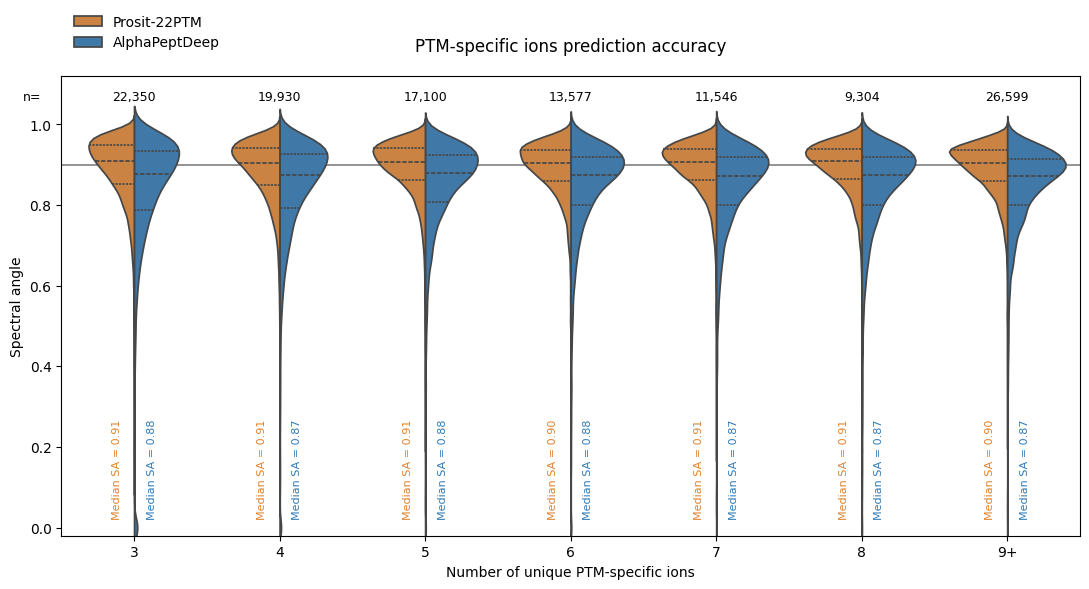

,ion_count_bin,n_PSMs,median_SA_Prosit-22PTM,median_SA_AlphaPeptDeep
0,3,22350,0.908846,0.878063
1,4,19930,0.905097,0.874719
2,5,17100,0.907250,0.878748
3,6,13577,0.903600,0.875202
4,7,11546,0.906496,0.872754
5,8,9304,0.908207,0.874134
6,9+,26599,0.904657,0.872442


In [3]:
ORDER = ['3', '4', '5', '6', '7', '8', '9+']


def ion_violin(parquet, title, xlabel, name):
    d = pd.read_parquet(fetch(parquet))
    long = d.melt(id_vars=['ion_count_bin'], value_vars=['spectral_angle_Prosit-22PTM', 'spectral_angle_AlphaPeptDeep'],
                  var_name='model', value_name='spectral_angle')
    long['model'] = long['model'].str.replace('spectral_angle_', '', regex=False)
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.violinplot(data=long, x='ion_count_bin', y='spectral_angle', hue='model', order=ORDER, split=True, inner='quart',
                   palette={'Prosit-22PTM': COLORS['Prosit-22PTM'], 'AlphaPeptDeep': COLORS['AlphaPeptDeep']}, ax=ax)
    ax.axhline(0.9, color='grey', lw=1.2, zorder=0)
    med = long.groupby(['ion_count_bin', 'model'])['spectral_angle'].median()
    n = d['ion_count_bin'].value_counts()
    for i, b in enumerate(ORDER):
        ax.text(i - 0.12, 0.02, f"Median SA = {med[(b, 'Prosit-22PTM')]:.2f}", rotation=90, ha='center', va='bottom',
                fontsize=8, color=COLORS['Prosit-22PTM'])
        ax.text(i + 0.12, 0.02, f"Median SA = {med[(b, 'AlphaPeptDeep')]:.2f}", rotation=90, ha='center', va='bottom',
                fontsize=8, color=COLORS['AlphaPeptDeep'])
        ax.text(i, 1.06, f"{n.get(b, 0):,}", ha='center', fontsize=9)
    ax.text(-0.7, 1.06, 'n=', ha='center', fontsize=9)
    ax.set_ylim(-0.02, 1.12)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Spectral angle')
    ax.set_title(title, pad=18)
    ax.legend(title='', loc='upper left', bbox_to_anchor=(0, 1.16), frameon=False)
    plt.tight_layout()
    save(name)


ion_violin('Wilhelm_SourceData_ED_Fig7a.parquet', 'PTM-specific ions prediction accuracy', 'Number of unique PTM-specific ions', 'ED_Fig7a')
table('ED_Fig7a')

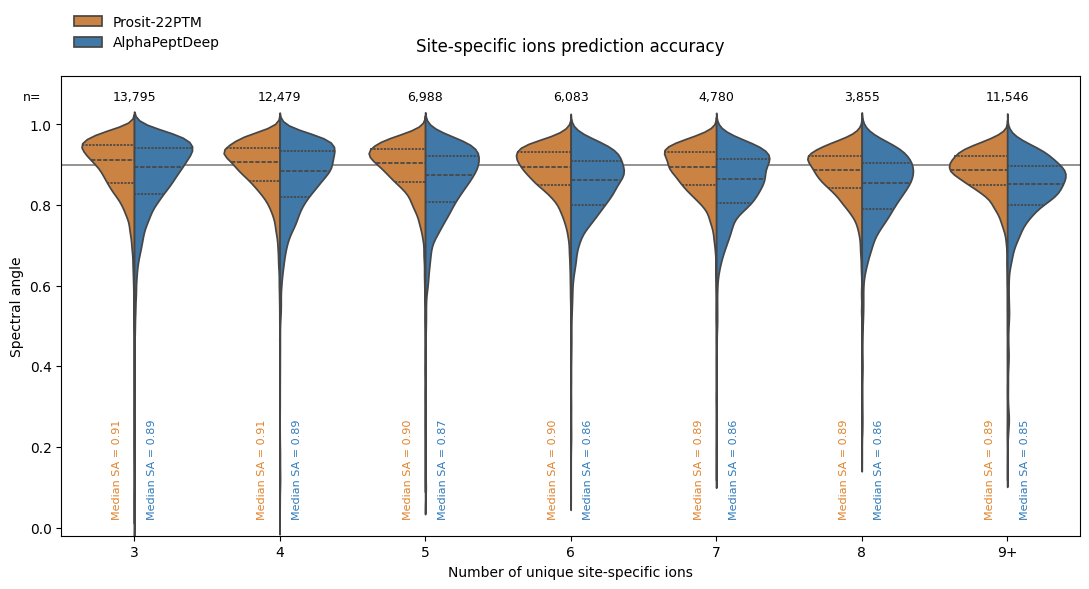

,ion_count_bin,n_PSMs,median_SA_Prosit-22PTM,median_SA_AlphaPeptDeep
0,3,13795,0.910798,0.893394
1,4,12479,0.907113,0.885191
2,5,6988,0.904209,0.873670
3,6,6083,0.895392,0.861475
4,7,4780,0.894203,0.863794
5,8,3855,0.887309,0.855245
6,9+,11546,0.887588,0.852135


In [4]:
ion_violin('Wilhelm_SourceData_ED_Fig7b.parquet', 'Site-specific ions prediction accuracy', 'Number of unique site-specific ions', 'ED_Fig7b')
table('ED_Fig7b')

## Panel c — Prosit-22PTM: localisation probability vs Percolator score

Precision–recall of phosphosite localisation (imp_pSTY pools, Orbitrap HCD), PSMs ranked by localisation probability or by Percolator score. In all precision–recall panels (c–j) colour = ranking, tool or model and line style = site context of the synthesised (true) site (solid = Non-adjacent, dashed = Adjacent); each curve is a smoothing spline (`scipy.interpolate.UnivariateSpline`, s = 0.005, same for every curve, clipped at 1) through the deposited per-rank points; dashed horizontal lines at precision 0.99 and 0.95.

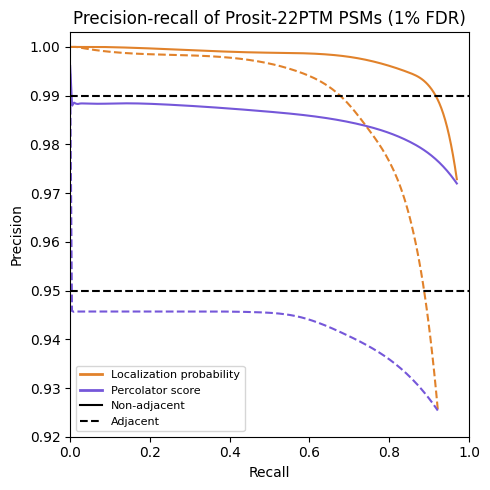

,ranking,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Localization probability,Non-adjacent,264138,256437,0.970845,0.969450,264518,0.915953,0.969450
1,Percolator score,Non-adjacent,264138,256437,0.970845,0.969450,264518,0.000907,0.969450
2,Localization probability,Adjacent,156934,145003,0.923974,0.921766,157310,0.676626,0.887916
3,Percolator score,Adjacent,156934,145003,0.923974,0.921766,157310,0.000318,0.001526


In [5]:
c = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig7c.parquet'))
CC = {'Localization probability': '#e1822b', 'Percolator score': '#7557d9'}
fig, ax = plt.subplots(figsize=(5, 5))
for (rk, ctx), g in c.groupby(['ranking', 'site_context']):
    x, y = fit_curve(g['recall_fraction'], g['precision_fraction'])
    ax.plot(x, y, color=CC[rk], ls=LS[ctx])
for y in (0.99, 0.95):
    ax.axhline(y, color='k', ls='--')
ax.set_xlim(0, 1.0); ax.set_ylim(0.92, 1.003)
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-recall of Prosit-22PTM PSMs (1% FDR)')
two_part_legend(ax, CC)
plt.tight_layout()
save('ED_Fig7c')
table('ED_Fig7c')

## Panels d–f — precision–recall per phosphorylated residue (Orbitrap HCD)

Precision–recall of phosphosite localisation for pS (d), pT (e) and pY (f) PSMs of the permutation pools, Prosit-22PTM vs MSFragger.

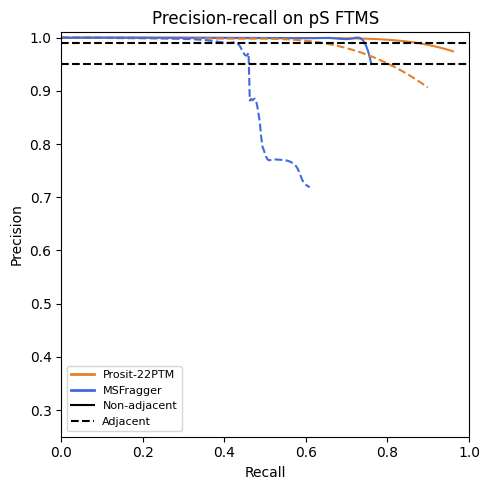

,tool,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Prosit-22PTM,Non-adjacent,6284,6073,0.966423,0.960766,6321,0.886252,0.960766
1,MSFragger,Non-adjacent,5112,4805,0.939945,0.760165,6321,0.749565,0.758741
2,Prosit-22PTM,Adjacent,4686,4234,0.903542,0.898557,4712,0.658744,0.800722
3,MSFragger,Adjacent,4043,2871,0.710116,0.609295,4712,0.428480,0.461163


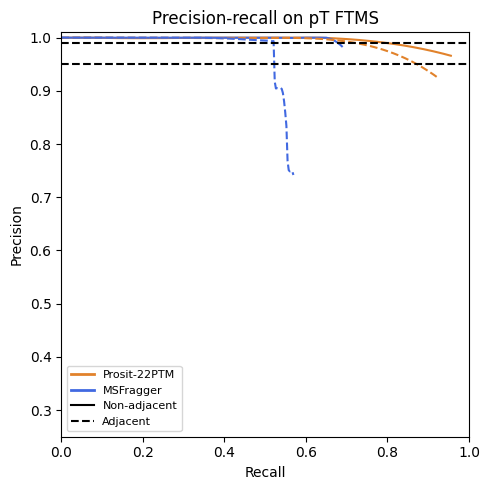

,tool,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Prosit-22PTM,Non-adjacent,3204,3071,0.958489,0.955507,3214,0.791226,0.955507
1,MSFragger,Non-adjacent,2291,2212,0.965517,0.688239,3214,0.681083,0.688239
2,Prosit-22PTM,Adjacent,3173,2928,0.922786,0.922495,3174,0.733774,0.869880
3,MSFragger,Adjacent,2449,1807,0.737852,0.569313,3174,0.523314,0.523314


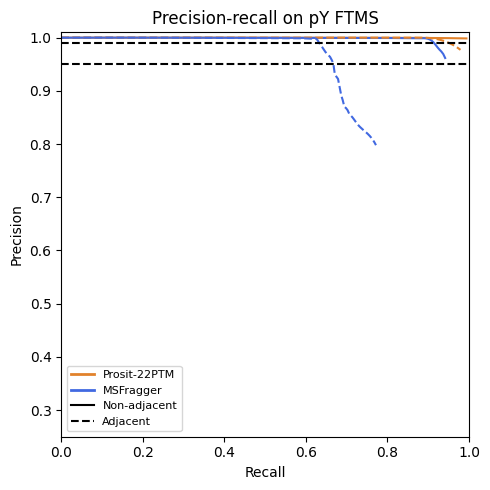

,tool,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Prosit-22PTM,Non-adjacent,87398,86921,0.994542,0.993701,87472,0.993701,0.993701
1,MSFragger,Non-adjacent,85506,82359,0.963196,0.941547,87472,0.912738,0.941547
2,Prosit-22PTM,Adjacent,41383,40535,0.979508,0.979106,41400,0.952005,0.979106
3,MSFragger,Adjacent,40290,31955,0.793125,0.771860,41400,0.632295,0.667440


In [6]:
def pr_plot(df, title, ylim, name, color_col='tool', colors=COLORS):
    fig, ax = plt.subplots(figsize=(5, 5))
    for (k, ctx), g in df.groupby([color_col, 'site_context'], sort=False):
        x, y = fit_curve(g['recall_fraction'], g['precision_fraction'])
        ax.plot(x, y, color=colors[k], ls=LS[ctx])
    for y in (0.99, 0.95):
        ax.axhline(y, color='k', ls='--')
    ax.set_xlim(0, 1); ax.set_ylim(*ylim)
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title(title)
    used = df[color_col].unique()
    two_part_legend(ax, {k: v for k, v in colors.items() if k in used})
    plt.tight_layout()
    save(name)


df_ = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig7d_f.parquet'))
for res, p in [('pS', 'd'), ('pT', 'e'), ('pY', 'f')]:
    pr_plot(df_[df_['residue'] == res], f'Precision-recall on {res} FTMS', (0.25, 1.01), f'ED_Fig7{p}')
    display(table(f'ED_Fig7{p}'))

## Panel g — Prosit intensity models (Orbitrap HCD)

Precision–recall of Prosit-22PTM localisation with four intensity models (Gain Loss / Atom Count PTM encoding, with / without augmentation; Prosit-22PTM = Gain Loss with Augmentation), permutation pools.

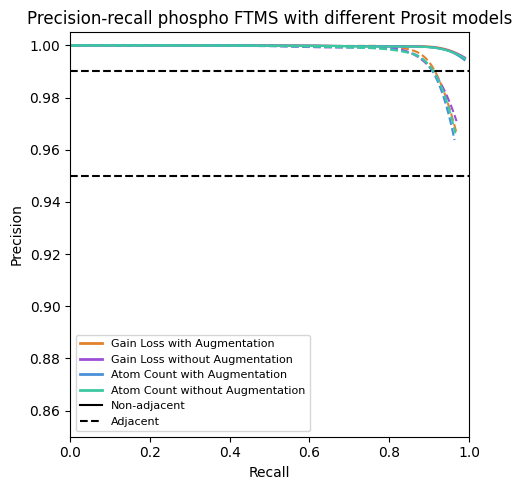

,model,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Gain Loss with Augmentation,Non-adjacent,96886,96065,0.991526,0.990289,97007,0.990289,0.990289
1,Gain Loss with Augmentation,Adjacent,49242,47697,0.968624,0.967760,49286,0.919227,0.967760
2,Gain Loss without Augmentation,Non-adjacent,96812,95957,0.991168,0.989574,96968,0.989574,0.989574
3,Gain Loss without Augmentation,Adjacent,49162,47712,0.970506,0.968772,49250,0.915431,0.968772
4,Atom Count with Augmentation,Non-adjacent,96760,95844,0.990533,0.988490,96960,0.988490,0.988490
5,Atom Count with Augmentation,Adjacent,49121,47444,0.965860,0.963721,49230,0.913671,0.963721
6,Atom Count without Augmentation,Non-adjacent,96790,95961,0.991435,0.989789,96951,0.989789,0.989789
7,Atom Count without Augmentation,Adjacent,49138,47550,0.967683,0.965874,49230,0.915803,0.965874


In [7]:
g7 = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig7g.parquet'))
MC = {'Gain Loss with Augmentation': '#e1822b', 'Gain Loss without Augmentation': '#9b4fd6',
      'Atom Count with Augmentation': '#4a90d9', 'Atom Count without Augmentation': '#3cc8a0'}
pr_plot(g7, 'Precision-recall phospho FTMS with different Prosit models', (0.85, 1.005), 'ED_Fig7g', color_col='model', colors=MC)
table('ED_Fig7g')

## Panels h, i — imp_pSTY pools, ion trap / Orbitrap (singly phosphorylated PSMs)

Precision–recall of phosphosite localisation, Prosit-22PTM vs MSFragger, ion-trap (ITMS, h) and Orbitrap (FTMS, i) scans.

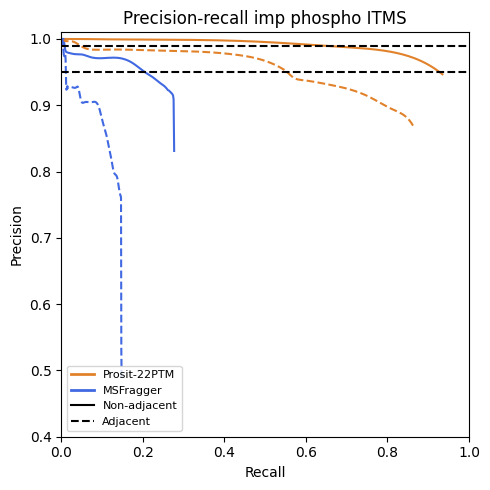

,tool,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Prosit-22PTM,Non-adjacent,10957,10305,0.940495,0.934779,11024,0.642779,0.923712
1,MSFragger,Non-adjacent,3628,3052,0.841235,0.276851,11024,0.008345,0.206368
2,Prosit-22PTM,Adjacent,6750,5885,0.871852,0.863283,6817,0.041954,0.549069
3,MSFragger,Adjacent,2058,1009,0.490282,0.148012,6817,0.004107,0.011295


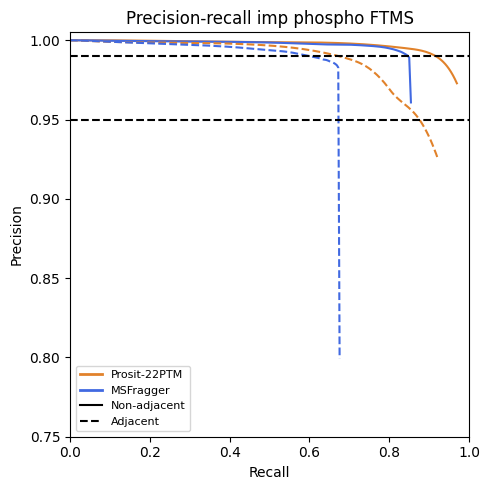

,tool,site_context,n_PSMs,n_correct,final_precision_fraction,final_recall_fraction,n_identified_union_scans (recall denominator),recall_at_precision>=0.99_fraction,recall_at_precision>=0.95_fraction
0,Prosit-22PTM,Non-adjacent,264129,256437,0.970878,0.969597,264478,0.916091,0.969597
1,MSFragger,Non-adjacent,236635,225984,0.954990,0.854453,264478,0.847345,0.854453
2,Prosit-22PTM,Adjacent,156920,145003,0.924057,0.922153,157244,0.673107,0.874997
3,MSFragger,Adjacent,131604,106247,0.807323,0.675682,157244,0.602198,0.675326


In [8]:
hi = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig7h_i.parquet'))
pr_plot(hi[hi['mass_analyzer'].str.startswith('ITMS')], 'Precision-recall imp phospho ITMS', (0.4, 1.01), 'ED_Fig7h')
display(table('ED_Fig7h'))
pr_plot(hi[hi['mass_analyzer'].str.startswith('FTMS')], 'Precision-recall imp phospho FTMS', (0.75, 1.005), 'ED_Fig7i')
table('ED_Fig7i')

## Panel j — localisation precision–recall per calibrated collision energy

Prosit-22PTM, imp_pSTY pools, Orbitrap HCD, all sites (adjacent + non-adjacent), singly phosphorylated PSMs; one curve per calibrated CE (legend n = PSMs per CE, `n_PSMs` of `Wilhelm_SourceData_ED_Fig7j.csv`). Inset: recall at precision ≥ 0.99 per CE (`recall_at_precision_0.99_fraction` of the same file).

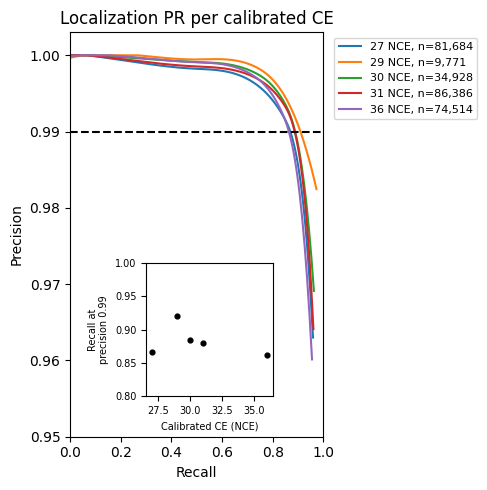

,calibrated_CE_NCE,n_PSMs,n_correctly_localised_PSMs,n_identified_union_scans (recall denominator),recall_at_precision_0.99_fraction
0,27,81684,78429,81797,0.865667
1,29,9771,9523,9793,0.920249
2,30,34928,33684,35004,0.883613
3,31,86386,83075,86505,0.880539
4,36,74514,71304,74670,0.861859


In [9]:
j = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig7j.parquet'))
js = table('ED_Fig7j')
fig, ax = plt.subplots(figsize=(5, 5))
cmap = plt.get_cmap('tab10')
for i, (ce, g) in enumerate(j.groupby('calibrated_CE_NCE')):
    x, y = fit_curve(g['recall_fraction'], g['precision_fraction'])
    n = js.set_index('calibrated_CE_NCE').loc[ce, 'n_PSMs']
    ax.plot(x, y, color=cmap(i % 10), label=f'{ce:.0f} NCE, n={n:,}')
ax.axhline(0.99, color='k', ls='--')
ax.set_xlim(0, 1); ax.set_ylim(0.95, 1.003)
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Localization PR per calibrated CE')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
ins = ax.inset_axes([0.30, 0.10, 0.50, 0.33])
ins.scatter(js['calibrated_CE_NCE'], js['recall_at_precision_0.99_fraction'], color='k', s=12)
ins.set_xlabel('Calibrated CE (NCE)', fontsize=7); ins.set_ylabel('Recall at\nprecision 0.99', fontsize=7)
ins.tick_params(labelsize=7); ins.set_ylim(0.8, 1.0)
plt.tight_layout()
save('ED_Fig7j')
js